# GridShift TFT — Notebook 01: Data Audit and Cleaning

This notebook audits and cleans the hourly India grid dataset. It displays tables and charts inline and **does not save cleaned datasets, scalers, reports, or plot images to disk**.

**Input expected:** `January 2024- June 2025.xlsx`, worksheet `Report`, with columns `Timestamp`, `Demand (MW)`, `Solar (MW)`, `Wind (MW)`, and `Total Generation (MW)`.

Place the workbook in `data/raw/` beside this notebook, or change `DATA_FILE` in Cell 1. The notebook reads only the hourly `Report` sheet, not older technical sheets with different sampling intervals.


In [2]:
# 1. Imports and configuration
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_FILE = Path("data/raw/January 2024- June 2025.xlsx")
SHEET_NAME = "Report"
TIMESTAMP_FORMAT = "%d-%m-%Y %H:%M:%S"

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
print("Working directory:", Path.cwd())
print("Expected workbook:", DATA_FILE.resolve())
print("File exists:", DATA_FILE.exists())


Working directory: d:\Github Repos\GridShift-TFT
Expected workbook: D:\Github Repos\GridShift-TFT\data\raw\January 2024- June 2025.xlsx
File exists: True


## 2. Load the workbook

If `File exists` is `False`, move the workbook to the displayed path or update `DATA_FILE` above. This notebook does not write output files.


In [3]:
# 2. Read the specified worksheet
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find: {DATA_FILE.resolve()}\n"
        "Place the workbook in data/raw/ or update DATA_FILE in Cell 1."
    )

raw_df = pd.read_excel(DATA_FILE, sheet_name=SHEET_NAME, header=0)
print(f"Loaded {len(raw_df):,} rows and {len(raw_df.columns)} columns")
display(raw_df.head(10))


Loaded 12,990 rows and 5 columns


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW)
0,01-01-2024 00:00:00,141981.26,9545.07,20.29,142193.38
1,01-01-2024 01:00:00,138675.49,9027.05,19.96,138792.04
2,01-01-2024 02:00:00,136122.78,8241.48,19.79,136796.02
3,01-01-2024 03:00:00,135806.51,7866.09,19.73,136859.67
4,01-01-2024 04:00:00,139905.77,7430.71,20.02,140561.49
5,01-01-2024 05:00:00,149576.68,6782.87,18.55,150273.8
6,01-01-2024 06:00:00,164183.48,5908.15,107.84,165184.35
7,01-01-2024 07:00:00,181403.35,5622.79,1570.77,182050.07
8,01-01-2024 08:00:00,195020.24,5153.53,9518.41,195333.03
9,01-01-2024 09:00:00,203050.27,3650.12,19207.05,203394.21


## 3. Inspect the raw data
Column names, data types, missing values, and descriptive statistics before cleaning.

In [4]:
# 3. Raw structure and missing-value audit
structure = pd.DataFrame({
    "column": raw_df.columns,
    "data_type": [str(dtype) for dtype in raw_df.dtypes],
    "missing_count": raw_df.isna().sum().values,
    "missing_percent": (raw_df.isna().mean().values * 100).round(3),
    "unique_values": [raw_df[c].nunique(dropna=True) for c in raw_df.columns],
})
display(structure)
display(raw_df.head())
display(raw_df.describe(include="all").T)


,column,data_type,missing_count,missing_percent,unique_values
0,Timestamp,object,0,0.0,12989
1,Demand (MW),object,0,0.0,12951
2,Wind (MW),object,0,0.0,12666
3,Solar (MW),object,0,0.0,12195
4,Total Generation (MW),object,0,0.0,12714


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW)
0,01-01-2024 00:00:00,141981.26,9545.07,20.29,142193.38
1,01-01-2024 01:00:00,138675.49,9027.05,19.96,138792.04
2,01-01-2024 02:00:00,136122.78,8241.48,19.79,136796.02
3,01-01-2024 03:00:00,135806.51,7866.09,19.73,136859.67
4,01-01-2024 04:00:00,139905.77,7430.71,20.02,140561.49


,count,unique,top,freq
Timestamp,12990,12989,Timestamp,2
Demand (MW),12990.0,12951.0,203763.52,11.0
Wind (MW),12990.0,12666.0,11065.84,87.0
Solar (MW),12990,12195,0,202
Total Generation (MW),12990.0,12714.0,212887.48,87.0


## 4. Validate columns and parse timestamps

Timestamps use day-month-year format, for example `01-01-2024 00:00:00`. Parsing is explicit so day/month values are not accidentally swapped.

In [5]:
# 4. Select required columns and parse types
required_cols = ["Timestamp", "Demand (MW)", "Solar (MW)", "Wind (MW)", "Total Generation (MW)"]
missing_cols = [c for c in required_cols if c not in raw_df.columns]
if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}\nFound: {list(raw_df.columns)}")

df = raw_df[required_cols].copy().rename(columns={
    "Timestamp": "timestamp",
    "Demand (MW)": "load_mw",
    "Solar (MW)": "solar_mw",
    "Wind (MW)": "wind_mw",
    "Total Generation (MW)": "total_generation_mw",
})
df["timestamp_original"] = df["timestamp"]
df["timestamp"] = pd.to_datetime(df["timestamp"], format=TIMESTAMP_FORMAT, errors="coerce")
numeric_cols = ["load_mw", "solar_mw", "wind_mw", "total_generation_mw"]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

bad_timestamps = df[df["timestamp"].isna()].copy()
print("Rows with unparseable timestamps:", len(bad_timestamps))
if len(bad_timestamps):
    display(bad_timestamps.head(20))


Rows with unparseable timestamps: 6


,timestamp,load_mw,solar_mw,wind_mw,total_generation_mw,timestamp_original
12984,NaT,0.000000e+00,-2.645590e+03,0.000000e+00,0.000000e+00,Minimum
12985,NaT,NaN,NaN,NaN,NaN,Timestamp
12986,NaT,2.918518e+05,6.548024e+04,3.472152e+04,2.597890e+05,Maximum
12987,NaT,NaN,NaN,NaN,NaN,Timestamp
12988,NaT,1.940100e+05,1.562369e+04,8.894010e+03,1.963000e+05,Average
12989,NaT,2.519026e+09,2.028580e+08,1.154799e+08,2.548759e+09,Sum


## 5. Duplicate timestamps and interval audit

We report duplicates and intervals first. Large numbers of duplicates or non-hourly intervals should be investigated before forecasting.

In [6]:
# 5. Timestamp and interval checks
valid_time_df = df[df["timestamp"].notna()].copy()
duplicate_timestamp_rows = valid_time_df[
    valid_time_df.duplicated(subset=["timestamp"], keep=False)
].sort_values("timestamp")
print("Rows involved in duplicate timestamps:", len(duplicate_timestamp_rows))
if len(duplicate_timestamp_rows):
    display(duplicate_timestamp_rows.head(30))

valid_time_df = valid_time_df.sort_values("timestamp").reset_index(drop=True)
time_diffs = valid_time_df["timestamp"].diff().dropna()
interval_counts = time_diffs.value_counts().rename_axis("time_interval").reset_index(name="count")
interval_counts["percent"] = (interval_counts["count"] / interval_counts["count"].sum() * 100).round(2)
print("Time range:", valid_time_df["timestamp"].min(), "to", valid_time_df["timestamp"].max())
print("Unique timestamps:", valid_time_df["timestamp"].nunique())
print("Exactly one-hour intervals:", int((time_diffs == pd.Timedelta(hours=1)).sum()))
print("Non-hourly intervals:", int((time_diffs != pd.Timedelta(hours=1)).sum()))
display(interval_counts.head(20))


Rows involved in duplicate timestamps: 0
Time range: 2024-01-01 00:00:00 to 2025-06-24 23:00:00
Unique timestamps: 12984
Exactly one-hour intervals: 12983
Non-hourly intervals: 0


,time_interval,count,percent
0,0 days 01:00:00,12983,100.0


## 6. Data-quality checks
Missing values and negative measurements are flagged for inspection; negative values are not automatically deleted.

In [7]:
# 6. Missingness and negative-value audit
quality = pd.DataFrame({
    "column": ["timestamp"] + numeric_cols,
    "missing_count": [valid_time_df["timestamp"].isna().sum()] +
                     [valid_time_df[c].isna().sum() for c in numeric_cols],
    "missing_percent": [valid_time_df["timestamp"].isna().mean() * 100] +
                       [valid_time_df[c].isna().mean() * 100 for c in numeric_cols],
})
quality["missing_percent"] = quality["missing_percent"].round(3)
display(quality)

negative_summary = pd.DataFrame({
    "column": numeric_cols,
    "negative_count": [(valid_time_df[c] < 0).sum() for c in numeric_cols],
})
display(negative_summary)
print("Rows with any missing numeric value:", int(valid_time_df[numeric_cols].isna().any(axis=1).sum()))


,column,missing_count,missing_percent
0,timestamp,0,0.0
1,load_mw,0,0.0
2,solar_mw,0,0.0
3,wind_mw,0,0.0
4,total_generation_mw,0,0.0


,column,negative_count
0,load_mw,0
1,solar_mw,499
2,wind_mw,0
3,total_generation_mw,0


Rows with any missing numeric value: 0


## 7. Visualize the raw time series
Charts display inline and are not saved as image files.

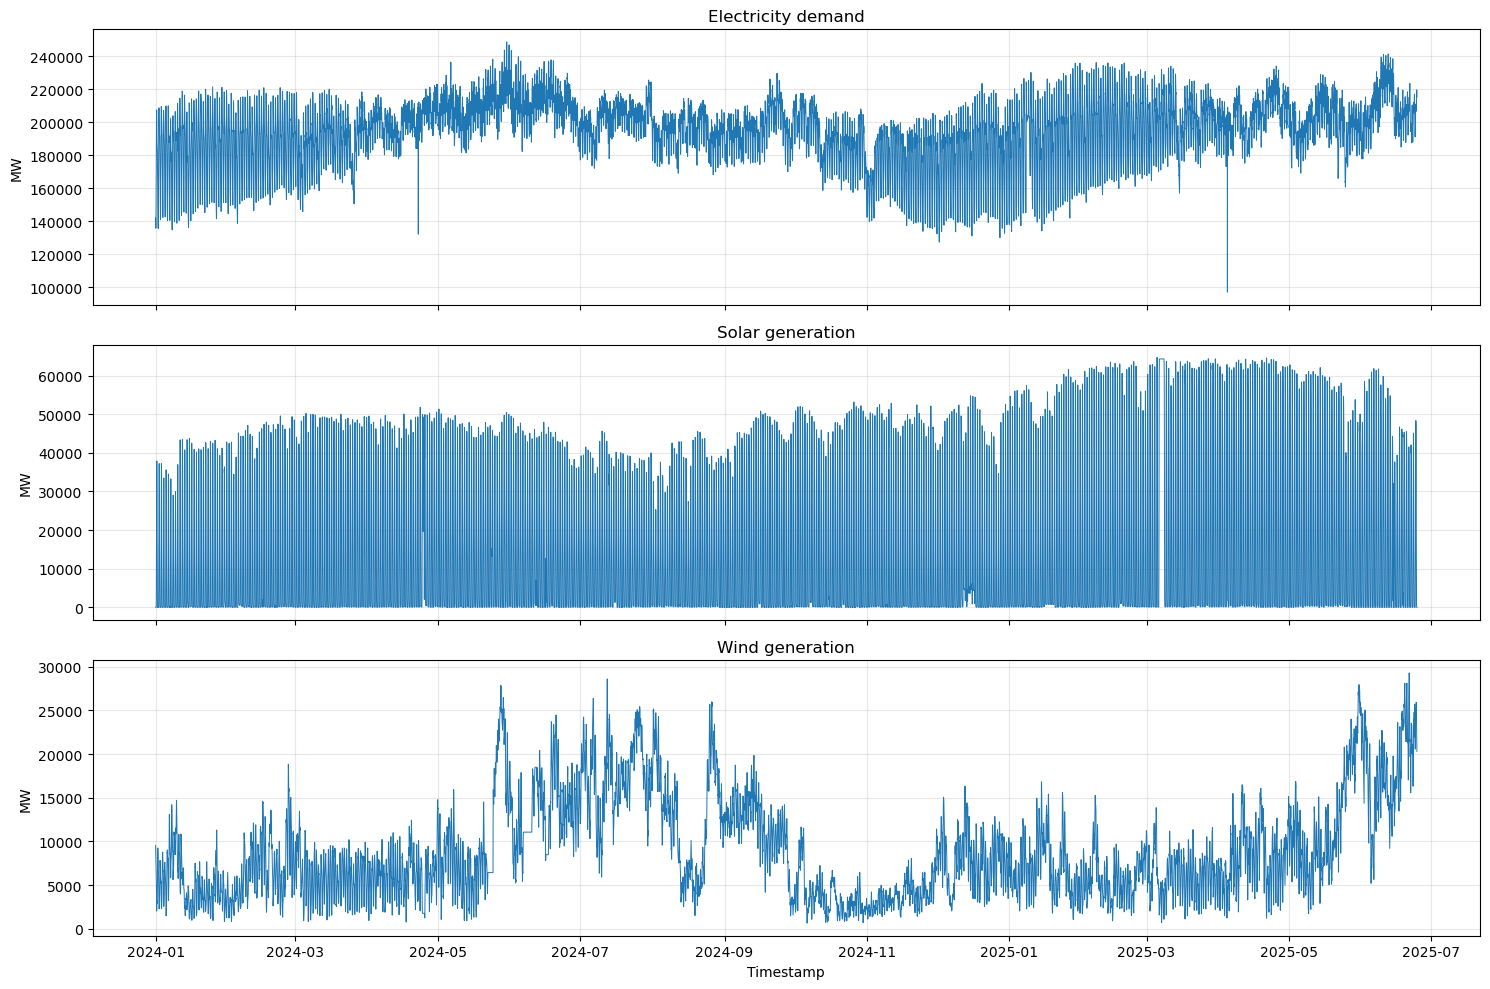

In [8]:
# 7. Raw time-series plots
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for ax, col, title in zip(
    axes, ["load_mw", "solar_mw", "wind_mw"],
    ["Electricity demand", "Solar generation", "Wind generation"]
):
    ax.plot(valid_time_df["timestamp"], valid_time_df[col], linewidth=0.7)
    ax.set_title(title)
    ax.set_ylabel("MW")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()


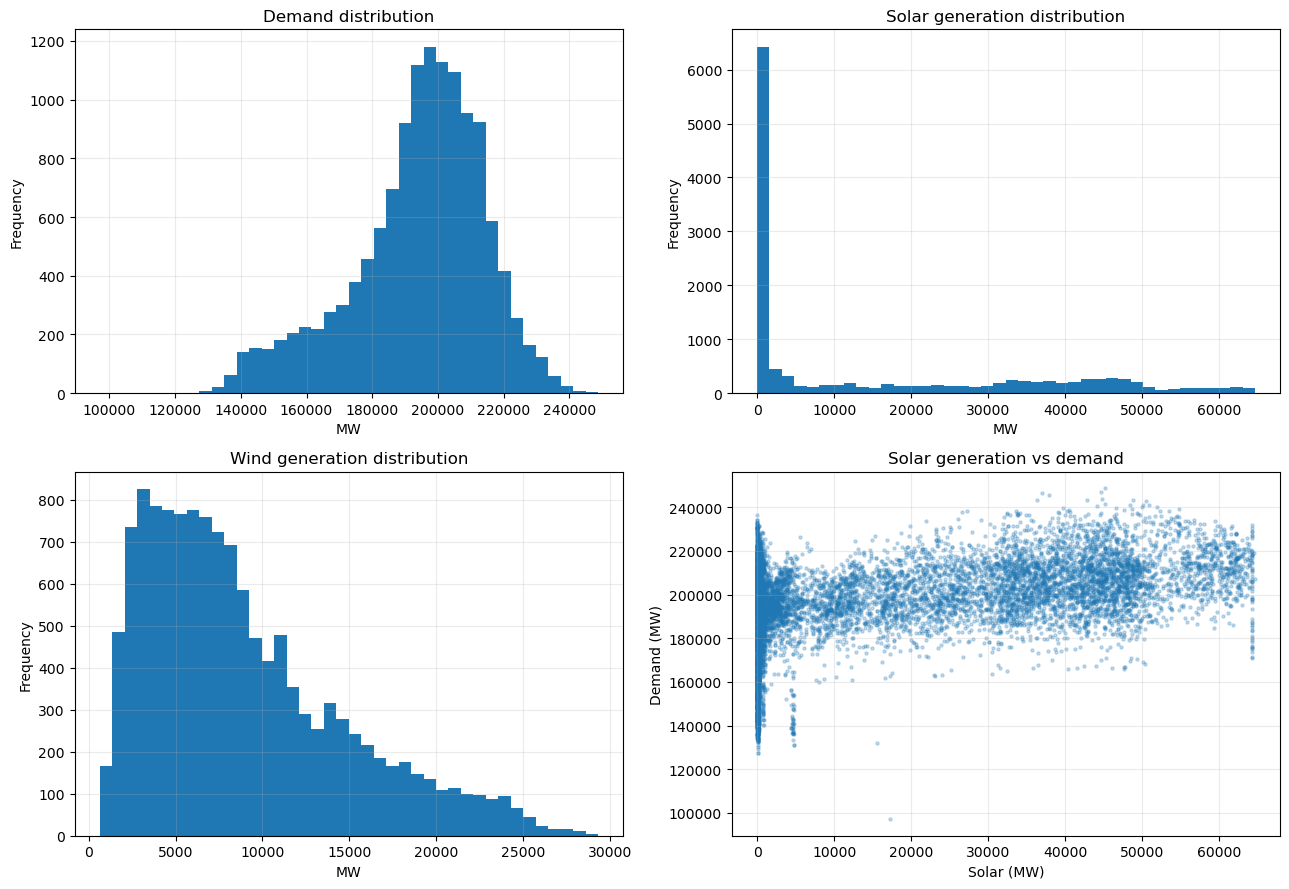

In [9]:
# 8. Distributions and solar-demand relationship
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col, title in [
    (axes[0, 0], "load_mw", "Demand distribution"),
    (axes[0, 1], "solar_mw", "Solar generation distribution"),
    (axes[1, 0], "wind_mw", "Wind generation distribution"),
]:
    ax.hist(valid_time_df[col].dropna(), bins=40)
    ax.set_title(title)
    ax.set_xlabel("MW")
    ax.set_ylabel("Frequency")
    ax.grid(True, alpha=0.25)
axes[1, 1].scatter(valid_time_df["solar_mw"], valid_time_df["load_mw"], s=5, alpha=0.25)
axes[1, 1].set_title("Solar generation vs demand")
axes[1, 1].set_xlabel("Solar (MW)")
axes[1, 1].set_ylabel("Demand (MW)")
axes[1, 1].grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Clean in memory only

Cleaning rules used here:
- Drop rows with unparseable timestamps.
- Sort chronologically.
- Keep the first row for duplicate timestamps and report how many were removed.
- Convert measurement columns to numeric values.
- Interpolate internal gaps of up to three consecutive hourly rows using time interpolation; longer gaps remain missing.
- Do not save any output files.

If the interval audit shows irregular sampling, investigate that before relying on interpolation or modeling.

In [10]:
# 9. Clean data in memory (no disk writes)
rows_before = len(df)
bad_timestamp_count = int(df["timestamp"].isna().sum())
clean_df = df[df["timestamp"].notna()].copy().sort_values("timestamp")
duplicate_rows_removed = int(clean_df.duplicated(subset=["timestamp"], keep="first").sum())
clean_df = clean_df.drop_duplicates(subset=["timestamp"], keep="first")
clean_df = clean_df.set_index("timestamp").sort_index()

missing_before_interpolation = clean_df[numeric_cols].isna().sum()
clean_df[numeric_cols] = clean_df[numeric_cols].interpolate(
    method="time", limit=3, limit_area="inside"
)
missing_after_interpolation = clean_df[numeric_cols].isna().sum()
clean_df = clean_df.reset_index()
clean_df["hour"] = clean_df["timestamp"].dt.hour
clean_df["day_of_week"] = clean_df["timestamp"].dt.dayofweek
clean_df["month"] = clean_df["timestamp"].dt.month
clean_df["day"] = clean_df["timestamp"].dt.day
clean_df["is_weekend"] = clean_df["day_of_week"].isin([5, 6])

print("Cleaned dataframe created in memory only.")
print(f"Rows before: {rows_before:,}")
print(f"Rows removed due to invalid timestamps: {bad_timestamp_count:,}")
print(f"Duplicate timestamp rows removed: {duplicate_rows_removed:,}")


Cleaned dataframe created in memory only.
Rows before: 12,990
Rows removed due to invalid timestamps: 6
Duplicate timestamp rows removed: 0


In [11]:
# 10. Missing values before and after interpolation
missing_comparison = pd.DataFrame({
    "column": numeric_cols,
    "missing_before_interpolation": missing_before_interpolation.values,
    "missing_after_interpolation": missing_after_interpolation.values,
})
display(missing_comparison)
print("Cleaned shape:", clean_df.shape)
display(clean_df.head(10))
display(clean_df.tail(10))


,column,missing_before_interpolation,missing_after_interpolation
0,load_mw,0,0
1,solar_mw,0,0
2,wind_mw,0,0
3,total_generation_mw,0,0


Cleaned shape: (12984, 11)


,timestamp,load_mw,solar_mw,wind_mw,total_generation_mw,timestamp_original,hour,day_of_week,month,day,is_weekend
0,2024-01-01 00:00:00,141981.26,20.29,9545.07,142193.38,01-01-2024 00:00:00,0,0,1,1,False
1,2024-01-01 01:00:00,138675.49,19.96,9027.05,138792.04,01-01-2024 01:00:00,1,0,1,1,False
2,2024-01-01 02:00:00,136122.78,19.79,8241.48,136796.02,01-01-2024 02:00:00,2,0,1,1,False
3,2024-01-01 03:00:00,135806.51,19.73,7866.09,136859.67,01-01-2024 03:00:00,3,0,1,1,False
4,2024-01-01 04:00:00,139905.77,20.02,7430.71,140561.49,01-01-2024 04:00:00,4,0,1,1,False
5,2024-01-01 05:00:00,149576.68,18.55,6782.87,150273.80,01-01-2024 05:00:00,5,0,1,1,False
6,2024-01-01 06:00:00,164183.48,107.84,5908.15,165184.35,01-01-2024 06:00:00,6,0,1,1,False
7,2024-01-01 07:00:00,181403.35,1570.77,5622.79,182050.07,01-01-2024 07:00:00,7,0,1,1,False
8,2024-01-01 08:00:00,195020.24,9518.41,5153.53,195333.03,01-01-2024 08:00:00,8,0,1,1,False
9,2024-01-01 09:00:00,203050.27,19207.05,3650.12,203394.21,01-01-2024 09:00:00,9,0,1,1,False


,timestamp,load_mw,solar_mw,wind_mw,total_generation_mw,timestamp_original,hour,day_of_week,month,day,is_weekend
12974,2025-06-24 14:00:00,210465.97,44698.83,25100.87,213258.30,24-06-2025 14:00:00,14,1,6,24,False
12975,2025-06-24 15:00:00,210731.24,37194.84,25938.18,212882.48,24-06-2025 15:00:00,15,1,6,24,False
12976,2025-06-24 16:00:00,208206.75,26095.50,25854.57,210242.69,24-06-2025 16:00:00,16,1,6,24,False
12977,2025-06-24 17:00:00,206808.15,14996.41,25596.34,208067.84,24-06-2025 17:00:00,17,1,6,24,False
12978,2025-06-24 18:00:00,208886.02,4935.21,24429.56,209621.02,24-06-2025 18:00:00,18,1,6,24,False
12979,2025-06-24 19:00:00,217525.28,561.23,24155.33,218132.01,24-06-2025 19:00:00,19,1,6,24,False
12980,2025-06-24 20:00:00,218591.04,-0.02,22126.62,219774.81,24-06-2025 20:00:00,20,1,6,24,False
12981,2025-06-24 21:00:00,219604.51,0.00,21730.31,220812.17,24-06-2025 21:00:00,21,1,6,24,False
12982,2025-06-24 22:00:00,219476.73,0.00,21207.32,220616.38,24-06-2025 22:00:00,22,1,6,24,False
12983,2025-06-24 23:00:00,215341.90,0.00,20314.42,216694.55,24-06-2025 23:00:00,23,1,6,24,False


## 9. Visualize cleaned series and typical patterns

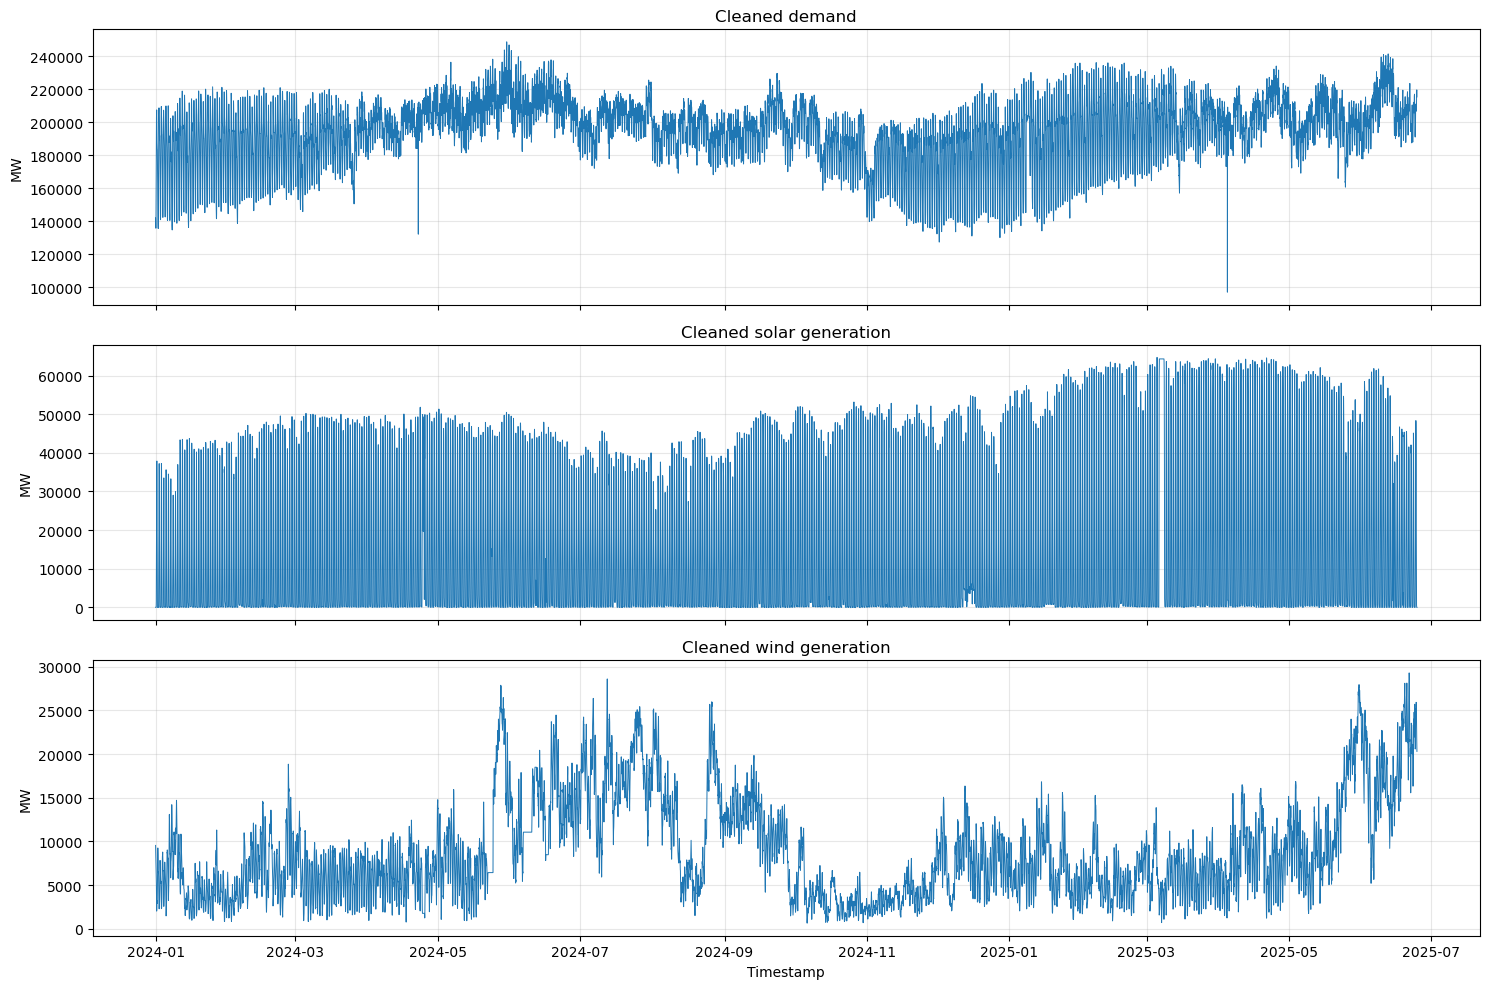

In [12]:
# 11. Cleaned time series
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for ax, col, title in zip(
    axes, ["load_mw", "solar_mw", "wind_mw"],
    ["Cleaned demand", "Cleaned solar generation", "Cleaned wind generation"]
):
    ax.plot(clean_df["timestamp"], clean_df[col], linewidth=0.7)
    ax.set_title(title)
    ax.set_ylabel("MW")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()


Average by hour of day (0 = midnight):


,load_mw,solar_mw,wind_mw
hour,,,
0,183079.53,441.52,10278.57
1,178654.32,444.38,10041.21
2,175000.88,486.50,9763.75
3,172852.82,473.75,9468.21
4,173858.89,474.83,9174.60
5,178740.04,402.99,8806.42
6,186788.65,1555.62,8411.09
7,194120.59,8278.99,7911.08
8,199366.35,21592.46,7511.24


Average by calendar month:


,load_mw,solar_mw,wind_mw
month,,,
1,183067.16,13275.70,6054.75
2,190172.13,15956.14,6260.90
3,193399.25,19157.59,5908.94
4,202160.19,18373.73,6989.08
5,204437.90,17348.56,11101.97
6,210276.53,15789.31,15844.19
7,202154.82,12640.08,17622.75
8,193538.88,12339.77,12418.29
9,195952.84,14349.82,11588.41


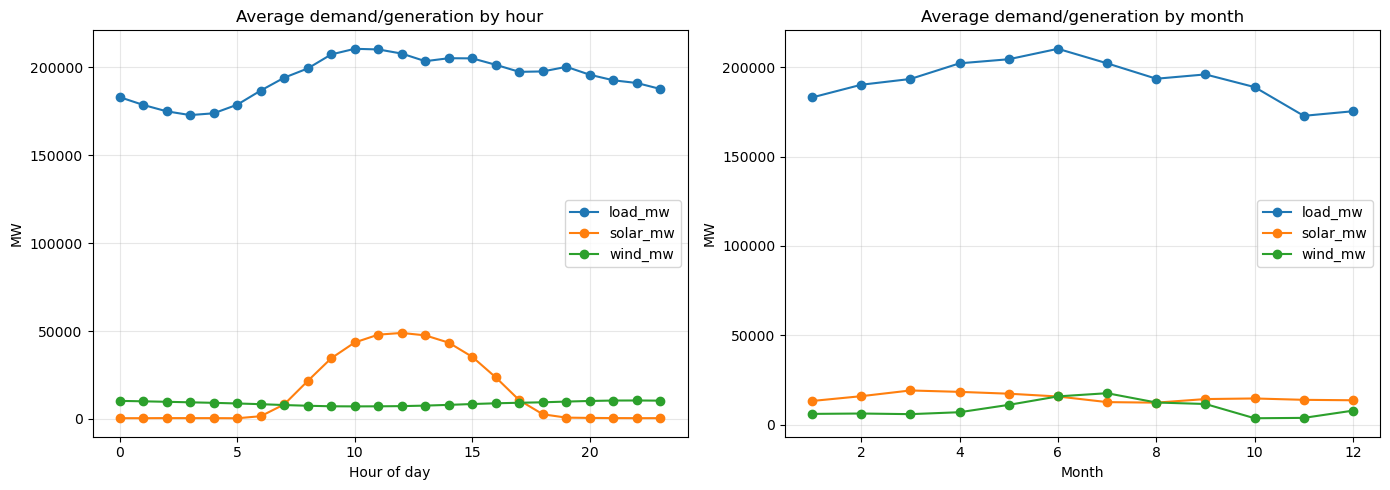

In [13]:
# 12. Average patterns by hour and calendar month
hourly_pattern = clean_df.groupby("hour")[["load_mw", "solar_mw", "wind_mw"]].mean().round(2)
monthly_pattern = clean_df.groupby("month")[["load_mw", "solar_mw", "wind_mw"]].mean().round(2)

print("Average by hour of day (0 = midnight):")
display(hourly_pattern)
print("Average by calendar month:")
display(monthly_pattern)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hourly_pattern.plot(ax=axes[0], marker="o")
axes[0].set_title("Average demand/generation by hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MW")
axes[0].grid(True, alpha=0.3)
monthly_pattern.plot(ax=axes[1], marker="o")
axes[1].set_title("Average demand/generation by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("MW")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,load_mw,solar_mw,wind_mw,total_generation_mw
load_mw,1.000,0.470,0.141,0.986
solar_mw,0.470,1.000,-0.199,0.469
wind_mw,0.141,-0.199,1.000,0.142
total_generation_mw,0.986,0.469,0.142,1.000


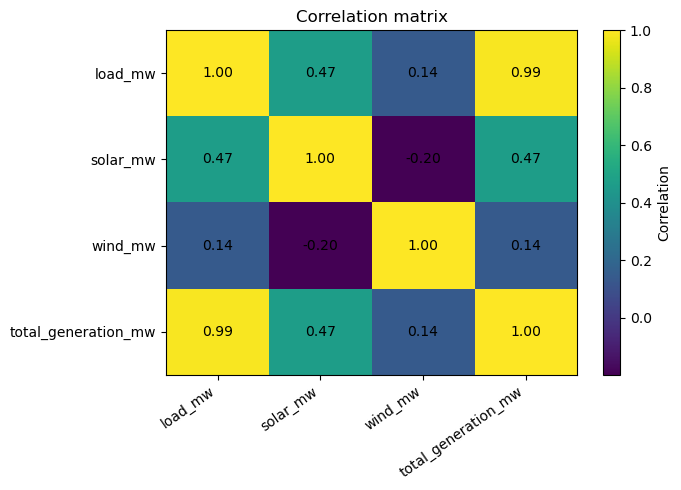

In [14]:
# 13. Correlation table and heatmap
corr = clean_df[numeric_cols].corr(numeric_only=True).round(3)
display(corr)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr.values, aspect="auto")
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr.index)), labels=corr.index)
ax.set_title("Correlation matrix")
fig.colorbar(im, ax=ax, label="Correlation")
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()


## 10. Final audit summary
Review this report before starting forecasting. No CSV, JSON, scaler, or plot files are created.

In [15]:
# 14. Final summary table
nonhourly_after_cleaning = int(
    (clean_df["timestamp"].diff().dropna() != pd.Timedelta(hours=1)).sum()
)
summary = pd.DataFrame([
    ("Input file", str(DATA_FILE)),
    ("Worksheet", SHEET_NAME),
    ("Original rows", rows_before),
    ("Rows with invalid timestamps", bad_timestamp_count),
    ("Duplicate timestamp rows removed", duplicate_rows_removed),
    ("Cleaned rows", len(clean_df)),
    ("Start timestamp", str(clean_df["timestamp"].min())),
    ("End timestamp", str(clean_df["timestamp"].max())),
    ("Non-hourly intervals after cleaning", nonhourly_after_cleaning),
    ("Numeric missing values remaining", int(clean_df[numeric_cols].isna().sum().sum())),
    ("Output saved to disk", "No"),
], columns=["check", "result"])
display(summary)
print("Notebook complete. The cleaned dataframe is available as `clean_df` in memory.")


,check,result
0,Input file,data\raw\January 2024- June 2025.xlsx
1,Worksheet,Report
2,Original rows,12990
3,Rows with invalid timestamps,6
4,Duplicate timestamp rows removed,0
5,Cleaned rows,12984
6,Start timestamp,2024-01-01 00:00:00
7,End timestamp,2025-06-24 23:00:00
8,Non-hourly intervals after cleaning,0
9,Numeric missing values remaining,0


Notebook complete. The cleaned dataframe is available as `clean_df` in memory.
